# Extended Data Fig. 6: normalisation and EnrichMap scores

Mouse brain Visium (raw counts) normalised five ways as in `07_normalisation_effect`, scored with EnrichMap (null). Every input uses the top 20 genes of each signature. Panels: a
total counts and variograms, b maps, c score distributions, d Spearman correlation between normalisations, e region recovery.
Source data are saved as CSV next to each figure.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns
import subprocess
import pickle

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from scipy.sparse import csr_matrix
from scipy.spatial.distance import pdist
from skgstat import Variogram
from sklearn.metrics import average_precision_score, roc_auc_score

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)
sc.settings.figdir = figure_dir

# processed data directory
processed_data = working_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

# results directory (tables without a figure)


In [5]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
}
spot_size = 20

In [6]:
# 1. Load data and signatures (07 cells 6-10)
adata = sq.datasets.visium_hne_adata()
adata.layers["counts"] = adata.raw.X.copy()
adata.X = adata.layers["counts"].copy()

cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"

with open("Pyramidal_layer_signatures.pkl", "rb") as f:
    pyramidal_dict = pickle.load(f)
with open("Striatum_signatures.pkl", "rb") as f:
    striatum_dict = pickle.load(f)
signature_dicts = {cell_type_1: pyramidal_dict, cell_type_2: striatum_dict}

# every input and panel uses the top 20 genes
gene_sets = {f"{ct}_top{n}": list(signature_dicts[ct][f"{ct}_top{n}"]) for ct in signature_dicts for n in (20,)}

regions = [cell_type_1, cell_type_2]
region_labels = {cell_type_1: "Pyramidal layer", cell_type_2: "Striatum"}
region_short = {cell_type_1: "Pyr", cell_type_2: "Str"}
labels = {ct: (adata.obs["cluster"] == ct).values.astype(int) for ct in regions}
coords = np.asarray(adata.obsm["spatial"], dtype=np.float64)

In [7]:
# 2. Normalisation layers (07 cells 14-22)
normalised = sc.pp.normalize_total(adata, target_sum=1e4, layer="counts", inplace=False)
adata.layers["log1p_norm"] = sc.pp.log1p(normalised["X"], copy=True)

scales_counts = sc.pp.normalize_total(adata, target_sum=None, layer="counts", inplace=False)
adata.layers["shifted_log"] = sc.pp.log1p(scales_counts["X"], copy=True)

# preliminary clustering for scran (normalize_total acts on layer "counts", so PCA, Leiden and
# computeSumFactors see log1p of the raw counts in X, as in 07 cell 18)
adata_pp = adata.copy()
sc.pp.normalize_total(adata_pp, layer="counts")
sc.pp.log1p(adata_pp)
sc.pp.pca(adata_pp, n_comps=15)
sc.pp.neighbors(adata_pp)
sc.tl.leiden(adata_pp, key_added="groups")
data_mat = csr_matrix(adata_pp.X.T)
input_groups = adata_pp.obs["groups"].astype(str).values
del adata_pp

# scran size factors: 07 cell 18 ran this R code through rpy2; scran is installed in the r_env R,
# so the matrix and the clusters are passed to its Rscript on stdin
rscript = os.environ.get("RSCRIPT", "Rscript")  # an R with scran and BiocParallel
r_code = """
suppressMessages({library(scran); library(BiocParallel); library(Matrix)})
con <- file("stdin", "rb")
dims <- readBin(con, integer(), 3, size = 4)
i <- readBin(con, integer(), dims[1], size = 4)
j <- readBin(con, integer(), dims[1], size = 4)
x <- readBin(con, double(), dims[1])
input_groups <- readBin(con, character(), dims[3])
data_mat <- sparseMatrix(i = i + 1, j = j + 1, x = x, dims = dims[2:3])
sce <- SingleCellExperiment(list(counts=data_mat))
size_factors = sizeFactors(computeSumFactors(sce, clusters = input_groups, min.mean = 0.1, BPPARAM = MulticoreParam(workers = 2)))
writeLines(format(size_factors, digits = 17))
"""
coo = data_mat.tocoo()
payload = (
    np.array([coo.nnz, *data_mat.shape], dtype=np.int32).tobytes()
    + coo.row.astype(np.int32).tobytes()
    + coo.col.astype(np.int32).tobytes()
    + coo.data.astype(np.float64).tobytes()
    + "\0".join(input_groups).encode() + b"\0"
)
run = subprocess.run([rscript, "--vanilla", "-e", r_code], input=payload, capture_output=True,
                     env={**os.environ, "OPENBLAS_NUM_THREADS": "4", "OMP_NUM_THREADS": "4"})
if run.returncode != 0:
    raise RuntimeError(f"Rscript failed ({run.returncode}):\n{run.stderr.decode()[-3000:]}")
size_factors = np.array(run.stdout.split(), dtype=np.float64)

adata.obs["size_factors"] = size_factors
scran = adata.X / adata.obs["size_factors"].values[:, None]
scran = csr_matrix(scran)
adata.layers["scran_norm"] = sc.pp.log1p(scran, copy=True)

analytic_pearson = sc.experimental.pp.normalize_pearson_residuals(adata, layer="counts", inplace=False)
adata.layers["analytic_pearson"] = csr_matrix(analytic_pearson["X"])

adata.layers["sqrt_norm"] = np.sqrt(sc.pp.normalize_total(adata, layer="counts", inplace=False)["X"])
print(f"Leiden clusters: {len(set(input_groups))}; size factors {size_factors.min():.3f}-{size_factors.max():.3f}")

normalisation_methods = ["log1p_norm", "shifted_log", "scran_norm", "analytic_pearson", "sqrt_norm"]
layer_keys = ["raw"] + normalisation_methods
map_order = ["raw", "log1p_norm", "shifted_log", "scran_norm", "sqrt_norm", "analytic_pearson"]  # published columns
plotted_size = {key: 20 for key in layer_keys}
log_based = ["log1p_norm", "shifted_log", "scran_norm", "sqrt_norm"]
method_labels = {
    "raw": "Raw counts",
    "log1p_norm": "Log1p",
    "shifted_log": "Shifted logarithm",
    "scran_norm": "Log1p with estimated size factors",
    "analytic_pearson": "Analytic Pearson residuals",
    "sqrt_norm": "Square root transformation",
}
short_labels = {
    "raw": "Raw counts",
    "log1p_norm": "Log1p",
    "shifted_log": "Shifted logarithm",
    "scran_norm": "Log1p with\nestimated size factors",
    "analytic_pearson": "Analytic Pearson\nresiduals",
    "sqrt_norm": "Square root\ntransformation",
}
# normalisation colours of the published panel a (tab10); markers for the region-recovery panel
norm_colours = {
    "raw": "#7f7f7f", "log1p_norm": "#1f77b4", "shifted_log": "#2ca02c", "scran_norm": "#8c564b",
    "analytic_pearson": "#7f7f7f", "sqrt_norm": "#17becf",
}
norm_markers = {"raw": "o", "log1p_norm": "s", "shifted_log": "^", "scran_norm": "D", "sqrt_norm": "v",
                "analytic_pearson": "X"}

# per-spot totals (Sup. Fig. 8a top, 07 cell 23)
totals = {"raw": adata.obs["total_counts"].values.astype(np.float64)}
for normalisation in normalisation_methods:
    totals[normalisation] = np.asarray(adata.layers[normalisation].sum(1)).ravel()

Leiden clusters: 22; size factors 0.147-3.311


In [8]:
# 3. EnrichMap: null model (default) and smoothing-only on every layer (07 cells 11 and 24: 6-NN, no batch)
variants = {
    "null": dict(null_model=True, correct_spatial_covariates=False, compute_q_vals=True),
}

# each layer is scored on a light copy (07 cell 24 scored a copy with X set to the layer)
p_empirical = {}
for key in layer_keys:
    light = sc.AnnData(
        X=adata.layers["counts"] if key == "raw" else adata.layers[key],
        obs=pd.DataFrame(index=adata.obs_names),
        var=pd.DataFrame(index=adata.var_names),
    )
    light.obsm["spatial"] = coords
    for variant, kwargs in variants.items():
        em.tl.score(
            light,
            gene_set={f"{name}_{key}_{variant}": genes for name, genes in gene_sets.items()},
            n_neighbors=6,
            smoothing=True,
            **kwargs,
        )
    adata.obs = adata.obs.join(light.obs)
    p_empirical.update({sig: info["p_empirical"] for sig, info in light.uns["null_model"].items()})
del light

  0%|          | 0/2 [00:00<?, ?it/s]

Scoring Pyramidal_layer_top20_raw_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]

Scoring Striatum_top20_raw_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]       

Scoring Striatum_top20_raw_null: 20/20 genes found: 100%|██████████| 2/2 [00:00<00:00, 28.42it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Scoring Pyramidal_layer_top20_log1p_norm_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]

... (16 outputs left out)

  0%|          | 0/2 [00:00<?, ?it/s]

Scoring Pyramidal_layer_top20_sqrt_norm_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]

Scoring Striatum_top20_sqrt_norm_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]       

Scoring Striatum_top20_sqrt_norm_null: 20/20 genes found: 100%|██████████| 2/2 [00:00<00:00, 28.85it/s]

In [9]:
# 4. Score column of each method
method_keys = {
    "EnrichMap (null)": "{name}_{key}_null_score",
}
methods = list(method_keys)
units = {
    "EnrichMap (null)": "z vs matched random genes",
}


def get_score(key, name, method):
    """
    Score per spot of one layer, gene set and method.

    Parameters
    ----------
    key : str
        Layer ("raw" or a normalisation).
    name : str
        Gene set, e.g. "Pyramidal_layer_top20".
    method : str
        Method label (key of `method_keys`).

    Returns
    -------
    np.ndarray
    """
    return adata.obs[method_keys[method].format(name=name, key=key)].values.astype(np.float64)

In [10]:
# 5. Region recovery: AUROC and AUPRC against the annotation, 95% CIs from 1,000 stratified spot bootstraps
n_boot = 1000
boot_index = {}
for ct in regions:
    # fixed number of annotated spots; the same resamples for every method and layer
    rng = np.random.default_rng(0)
    pos, neg = np.flatnonzero(labels[ct] == 1), np.flatnonzero(labels[ct] == 0)
    boot_index[ct] = [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n_boot)]


def bootstrap_ci(y, s, resamples):
    """
    95% percentile intervals of AUROC and AUPRC over stratified spot bootstraps.

    Parameters
    ----------
    y : np.ndarray
        Binary annotation per spot.
    s : np.ndarray
        Score per spot.
    resamples : list of np.ndarray
        Spot indices of each bootstrap sample (positives and negatives resampled separately).

    Returns
    -------
    dict
        AUROC_lo, AUROC_hi, AUPRC_lo, AUPRC_hi and "CI widened". Spots are spatially autocorrelated, so these
        intervals are lower bounds of the uncertainty. Where the percentile interval excludes the point estimate
        (tied resampled positives bias the bootstrap AUPRC), it is widened to include it.
    """
    est_r, est_p = roc_auc_score(y, s), average_precision_score(y, s)
    auroc = [roc_auc_score(y[idx], s[idx]) for idx in resamples]
    auprc = [average_precision_score(y[idx], s[idx]) for idx in resamples]
    lo_r, hi_r = np.percentile(auroc, [2.5, 97.5])
    lo_p, hi_p = np.percentile(auprc, [2.5, 97.5])
    widened = bool(lo_r > est_r or hi_r < est_r or lo_p > est_p or hi_p < est_p)
    return {"AUROC_lo": min(lo_r, est_r), "AUROC_hi": max(hi_r, est_r), "AUPRC_lo": min(lo_p, est_p),
            "AUPRC_hi": max(hi_p, est_p), "CI widened": widened}


summary_rows = []
for ct in regions:
    y = labels[ct]
    for key in layer_keys:
        for n in (20,):
            name = f"{ct}_top{n}"
            for m in methods:
                s = get_score(key, name, m)
                row = {
                    "region": region_labels[ct], "normalisation": method_labels[key], "layer": key, "gene set size": n,
                    "plotted": n == plotted_size[key], "method": m, "AUROC": roc_auc_score(y, s),
                    "AUPRC": average_precision_score(y, s), "prevalence": y.mean(), "min": s.min(),
                    "median": np.median(s), "max": s.max(), "fraction > 0": np.mean(s > 0),
                }
                # CIs only for the plotted gene-set size of each layer
                ci = bootstrap_ci(y, s, boot_index[ct]) if n == plotted_size[key] else {}
                row.update({k: ci.get(k, np.nan) for k in ("AUROC_lo", "AUROC_hi", "AUPRC_lo", "AUPRC_hi", "CI widened")})
                if m == "EnrichMap (null)":
                    pe = p_empirical[f"{name}_{key}_null"]
                    row.update({
                        "z > 0 in region": np.mean(s[y == 1] > 0),
                        "z > 0 outside region": np.mean(s[y == 0] > 0),
                        "z > 1.96 in region": np.mean(s[y == 1] > 1.96),
                        "z > 1.96 outside region": np.mean(s[y == 0] > 1.96),
                        "z < -1.96 outside region": np.mean(s[y == 0] < -1.96),
                        "p_empirical <= 0.05 in region": np.mean(pe[y == 1] <= 0.05),
                        "p_empirical <= 0.05 outside region": np.mean(pe[y == 0] <= 0.05),
                    })
                summary_rows.append(row)
recovery = pd.DataFrame(summary_rows)
plotted_recovery = recovery[recovery["plotted"]].copy()
print(plotted_recovery.pivot_table(index=["region", "normalisation"], columns="method", values="AUROC", sort=False)
      [methods].round(3).to_string())
print(plotted_recovery.pivot_table(index=["region", "normalisation"], columns="method", values="AUPRC", sort=False)
      [methods].round(3).to_string())
print(f"intervals widened to include the estimate: {int(plotted_recovery['CI widened'].sum())} of {len(plotted_recovery)}")

method                                             EnrichMap (null)
region          normalisation                                      
Pyramidal layer Raw counts                                    0.993
                Log1p                                         0.996
                Shifted logarithm                             0.996
                Log1p with estimated size factors             0.996
                Analytic Pearson residuals                    0.009
                Square root transformation                    0.996
Striatum        Raw counts                                    0.991
                Log1p                                         0.993
                Shifted logarithm                             0.993
                Log1p with estimated size factors             0.993
                Analytic Pearson residuals                    0.089
                Square root transformation                    0.994
method                                          

In [11]:
# 6. Spearman correlation between normalisations (07 cell 27; top 20 genes), every method
spearman = {}
for ct in regions:
    for m in methods:
        df_corr = pd.DataFrame({key: get_score(key, f"{ct}_top20", m) for key in normalisation_methods})
        spearman[(ct, m)] = df_corr.corr(method="spearman")

summary_rows = []
for ct in regions:
    for m in methods:
        c = spearman[(ct, m)]
        for r in normalisation_methods:
            for k in normalisation_methods:
                summary_rows.append({"region": region_labels[ct], "method": m, "row": method_labels[r],
                                     "column": method_labels[k], "spearman_rho": c.loc[r, k]})
spearman_long = pd.DataFrame(summary_rows)

summary_rows = []
for ct in regions:
    for m in methods:
        c = spearman[(ct, m)]
        sub = c.loc[log_based, log_based].values
        summary_rows.append({
            "region": region_labels[ct], "method": m,
            "min rho among log-based": sub[~np.eye(len(log_based), dtype=bool)].min(),
            "Pearson residuals vs log-based (min)": c.loc["analytic_pearson", log_based].min(),
            "Pearson residuals vs log-based (max)": c.loc["analytic_pearson", log_based].max(),
        })
rho_summary = pd.DataFrame(summary_rows)
print(rho_summary.round(3).to_string(index=False))

         region           method  min rho among log-based  Pearson residuals vs log-based (min)  Pearson residuals vs log-based (max)
Pyramidal layer EnrichMap (null)                    0.975                                -0.531                                -0.494
       Striatum EnrichMap (null)                    0.974                                -0.551                                -0.518


In [12]:
# 7. Variograms of the panel b scores (computed as in em.pl.variogram_all; experimental values)
max_lag = np.percentile(pdist(coords), 95)  # x-axis limit of em.pl.variogram_all


def variogram_table(values):
    """
    Experimental variogram as computed by em.pl.variogram_all (Cressie estimator, 10 lag bins).

    Parameters
    ----------
    values : np.ndarray
        Score per spot.

    Returns
    -------
    pd.DataFrame
        One row per lag bin: upper bin edge, semivariance, number of pairs, the variance of the score
        (dashed line of the plot) and the semivariance divided by that variance.
    """
    V = Variogram(coords, values, method="cressie", model="gaussian", fit_method=None, verbose=False)
    var = np.var(values)
    return pd.DataFrame({
        "lag_bin": np.arange(1, len(V.bins) + 1), "lag_bin_upper_edge_px": V.bins, "semivariance": V.experimental,
        "n_pairs": V.bin_count, "variance": var, "semivariance / variance": V.experimental / var,
        "inside_plotted_x_range": V.bins <= max_lag,
    })


frames = []
for ct in regions:
    for key in map_order:
        name = f"{ct}_top{plotted_size[key]}"
        for m in methods:
            frames.append(variogram_table(get_score(key, name, m)).assign(
                region=region_labels[ct], normalisation=method_labels[key], gene_set=name, method=m))
variograms = pd.concat(frames, ignore_index=True)
first_lag = variograms[variograms["lag_bin"] == 1].pivot_table(
    index=["region", "normalisation"], columns="method", values="semivariance / variance", sort=False)[methods]
print("semivariance / variance at the first lag bin (lower = smoother at short range)")
print(first_lag.round(3).to_string())

semivariance / variance at the first lag bin (lower = smoother at short range)
method                                             EnrichMap (null)
region          normalisation                                      
Pyramidal layer Raw counts                                    0.711
                Log1p                                         0.653
                Shifted logarithm                             0.647
                Log1p with estimated size factors             0.652
                Square root transformation                    0.637
                Analytic Pearson residuals                    0.738
Striatum        Raw counts                                    0.737
                Log1p                                         0.650
                Shifted logarithm                             0.659
                Log1p with estimated size factors             0.655
                Square root transformation                    0.669
                Analytic Pearson resi

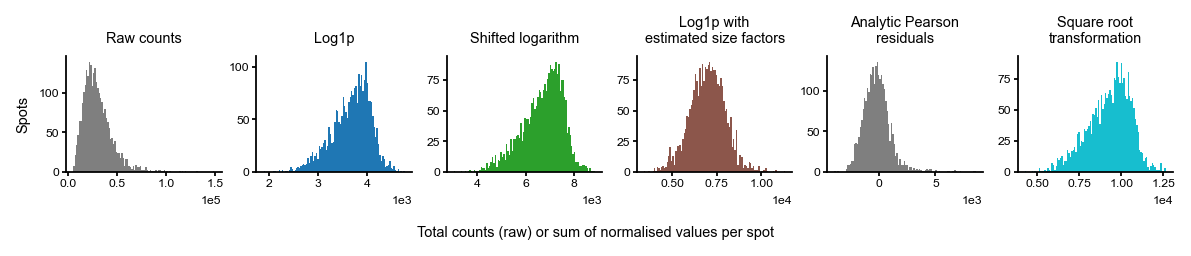

In [13]:
# 8. Sup. Fig. 8a (top): per-spot totals after each normalisation (07 cell 23)
fig, axes = plt.subplots(1, 6, figsize=(7.4, 1.35))
for ax, key in zip(axes, ["raw", "log1p_norm", "shifted_log", "scran_norm", "analytic_pearson", "sqrt_norm"]):
    ax.hist(totals[key], bins=100, color=norm_colours[key], linewidth=0)
    ax.set_title(short_labels[key], fontsize=6.5)
    ax.tick_params(labelsize=5.5, length=2, pad=1)
    ax.ticklabel_format(axis="x", style="sci", scilimits=(-2, 3))
    ax.xaxis.offsetText.set_fontsize(5.5)
    ax.grid(False)
    sns.despine(ax=ax)
axes[0].set_ylabel("Spots", fontsize=6.5)
fig.text(0.5, -0.08, "Total counts (raw) or sum of normalised values per spot", ha="center", fontsize=6.5)
plt.tight_layout(w_pad=0.6)
plt.savefig(figure_dir + "ExtendedDataFig6a_total_counts.pdf", bbox_inches="tight")
plt.show()
pd.DataFrame({method_labels[k]: v for k, v in totals.items()}, index=adata.obs_names).to_csv(
    source_dir + "ExtendedDataFig6a_total_counts.csv")

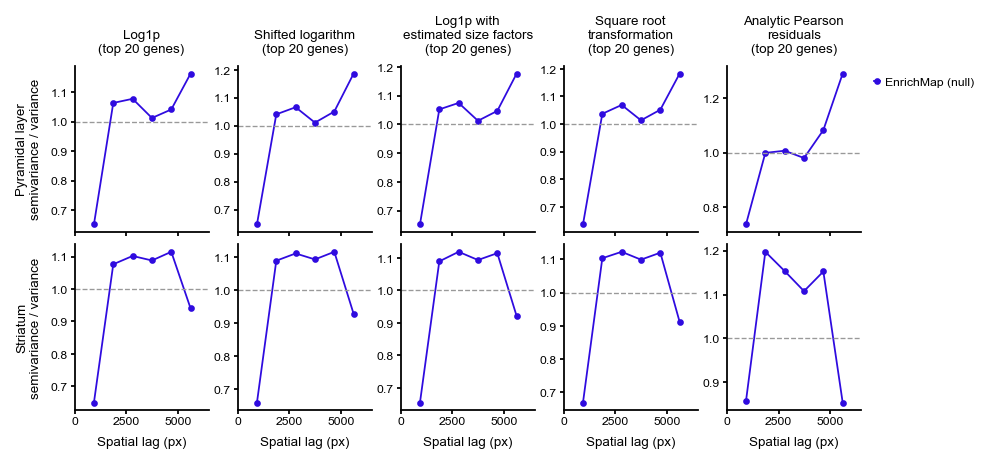

In [14]:
# 9. Extended Data Fig. 6a (bottom): variograms of the normalised scores (semivariance / variance)
variogram_keys = [k for k in map_order if k != "raw"]
fig, axes = plt.subplots(2, 5, figsize=(6.2, 2.9), sharex=True)
for i, ct in enumerate(regions):
    for k, key in enumerate(variogram_keys):
        ax = axes[i, k]
        for m in methods:
            d = variograms[(variograms["region"] == region_labels[ct]) & (variograms["normalisation"] == method_labels[key])
                           & (variograms["method"] == m) & variograms["inside_plotted_x_range"]]
            ax.plot(d["lag_bin_upper_edge_px"], d["semivariance / variance"], "o-", color=colours[m], ms=2, lw=0.8, label=m)
        ax.axhline(1, ls="--", c="0.6", lw=0.6)
        ax.set_xlim(0, max_lag)
        if i == 0:
            ax.set_title(f"{short_labels[key]}\n(top {plotted_size[key]} genes)", fontsize=6)
        ax.tick_params(labelsize=5.5, length=2, pad=1)
        ax.grid(False)
        sns.despine(ax=ax)
    axes[i, 0].set_ylabel(f"{region_labels[ct]}\nsemivariance / variance", fontsize=6)
for ax in axes[1]:
    ax.set_xlabel("Spatial lag (px)", fontsize=6)
axes[0, -1].legend(frameon=False, fontsize=5.5, loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout(w_pad=0.4, h_pad=0.6)
plt.savefig(figure_dir + "ExtendedDataFig6a_variograms.pdf", bbox_inches="tight")
plt.show()
variograms[variograms["normalisation"] != method_labels["raw"]].to_csv(
    source_dir + "ExtendedDataFig6a_variograms.csv", index=False)

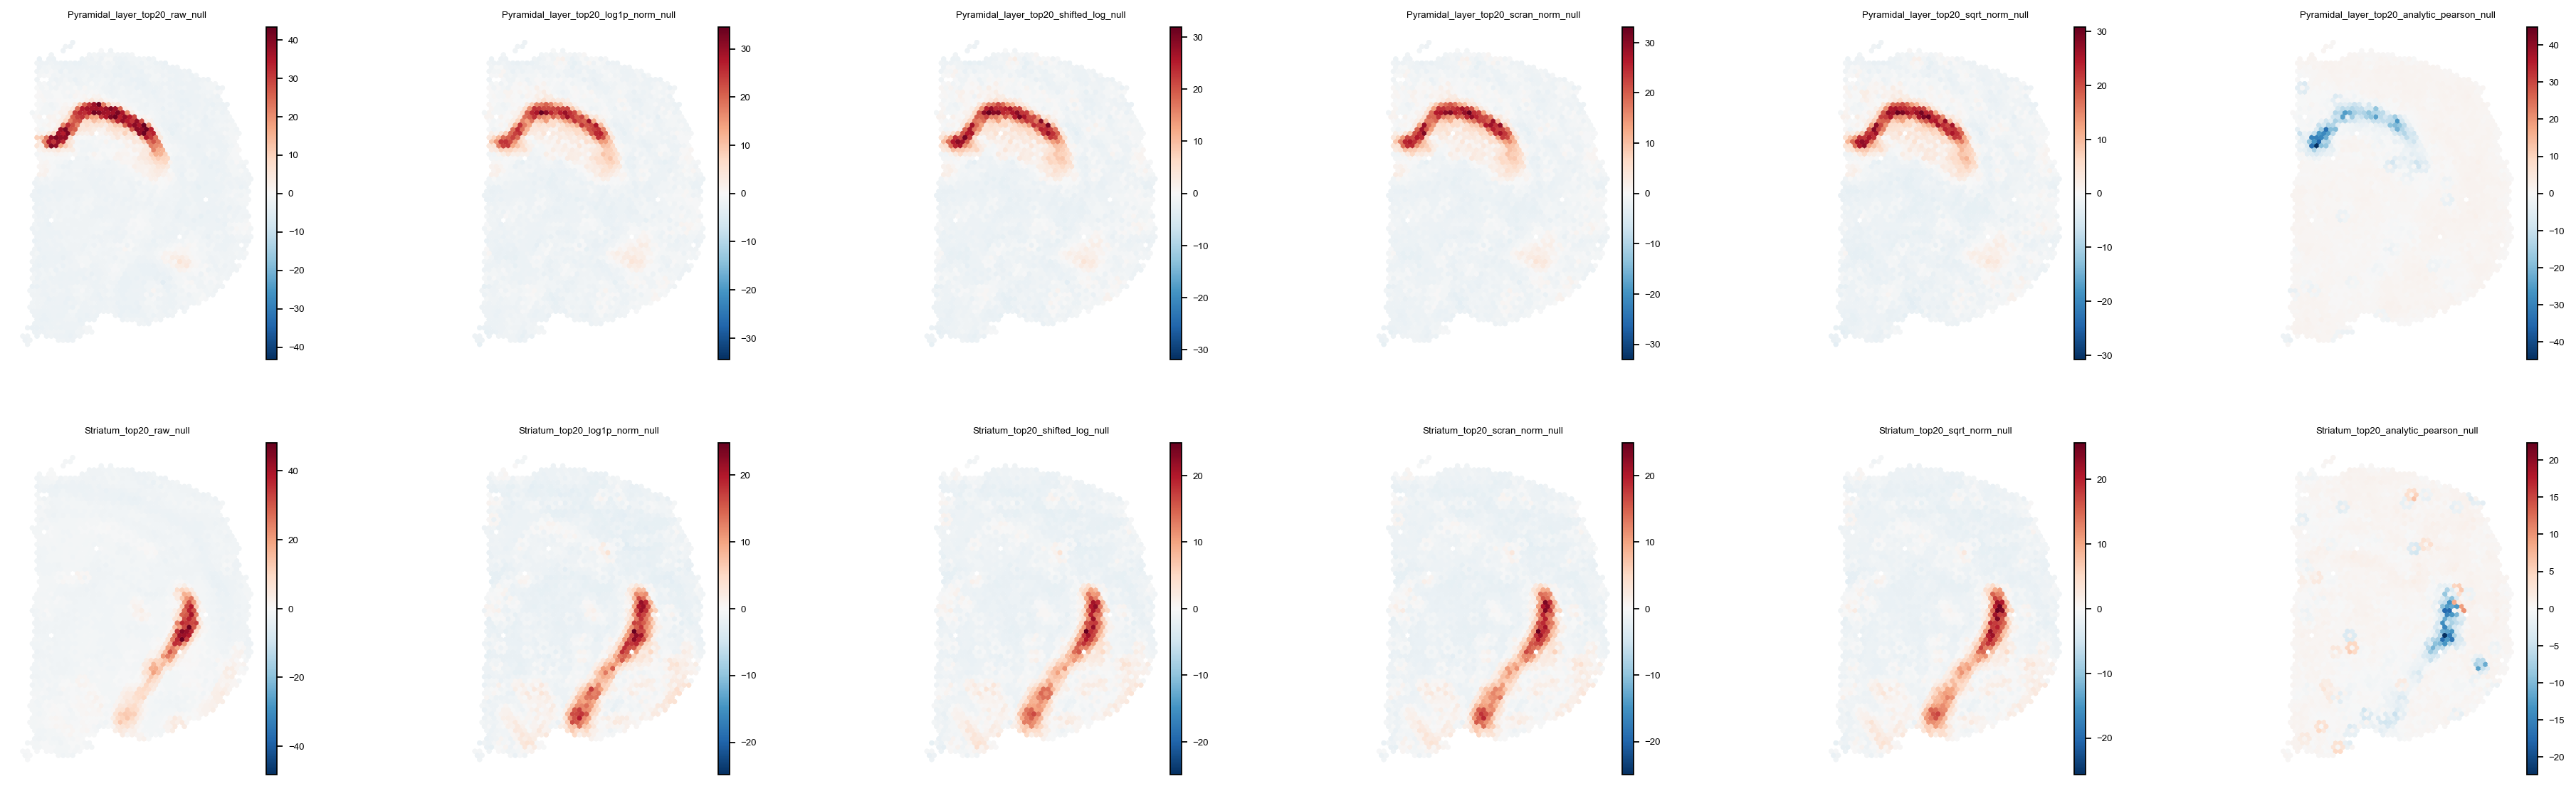

In [15]:
# 10. Extended Data Fig. 6b: score maps per normalisation, centred at 0; rows = regions, columns = raw counts and the five
# normalisations (published order)
keys = [method_keys[m].format(name=f"{ct}_top{plotted_size[key]}", key=key)
        for ct in regions for m in methods for key in map_order]
em.pl.spatial_enrichmap(adata, score_key=keys, vcenter=0, ncols=6, save="ExtendedDataFig6b_maps.pdf", shape=None,
                        size=spot_size)
maps = adata.obs[keys].copy()
maps.insert(0, "y", coords[:, 1])
maps.insert(0, "x", coords[:, 0])
maps.to_csv(source_dir + "ExtendedDataFig6b_maps.csv")

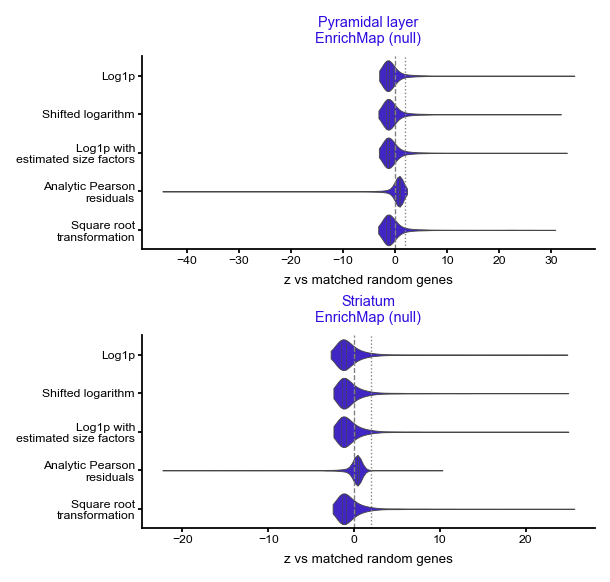

In [16]:
# 11. Sup. Fig. 8c: score distributions per normalisation
# Width-scaled violins, quartiles, bw 0.2, cut 0

frames = []
for ct in regions:
    for key in normalisation_methods:
        for m in methods:
            frames.append(
                pd.DataFrame(
                    {
                        "region": region_labels[ct],
                        "normalisation": method_labels[key],
                        "method": m,
                        "spot_id": adata.obs_names,
                        "score": get_score(key, f"{ct}_top20", m),
                    }
                )
            )

panel_c = pd.concat(frames, ignore_index=True)

violin_order = [method_labels[k] for k in normalisation_methods]

# FIX: squeeze=False ensures axes is always 2D
fig, axes = plt.subplots(
    len(regions),
    len(methods),
    figsize=(3.8 * len(methods), 1.8 * len(regions)),
    sharey=True,
    squeeze=False,
)

for i, ct in enumerate(regions):
    for j, m in enumerate(methods):
        ax = axes[i, j]

        d = panel_c[(panel_c["region"] == region_labels[ct]) & (panel_c["method"] == m)]

        sns.violinplot(
            data=d,
            x="score",
            y="normalisation",
            order=violin_order,
            density_norm="width",
            inner="quartile",
            bw_method=0.2,
            cut=0,
            color=colours[m],
            linewidth=0.4,
            ax=ax,
        )

        ax.axvline(0, color="grey", linestyle="--", lw=0.6)

        if m == "EnrichMap (null)":
            ax.axvline(1.96, color="grey", linestyle=":", lw=0.6)

        ax.set_title(f"{region_labels[ct]}\n{m}", fontsize=6.5, color=colours[m])
        ax.set_xlabel(units[m], fontsize=6)
        ax.set_ylabel("")
        ax.set_yticks(range(len(violin_order)))
        ax.set_yticklabels([short_labels[k] for k in normalisation_methods], fontsize=6)
        ax.tick_params(labelsize=5.5, length=2, pad=1)
        ax.ticklabel_format(axis="x", style="sci", scilimits=(-2, 3))
        ax.xaxis.offsetText.set_fontsize(5.5)
        ax.grid(False)
        sns.despine(ax=ax)

plt.tight_layout(w_pad=0.5, h_pad=0.8)

plt.savefig(
    figure_dir + "ExtendedDataFig6c_score_distributions.pdf", bbox_inches="tight"
)
plt.show()

panel_c.to_csv(source_dir + "ExtendedDataFig6c_score_distributions.csv", index=False)

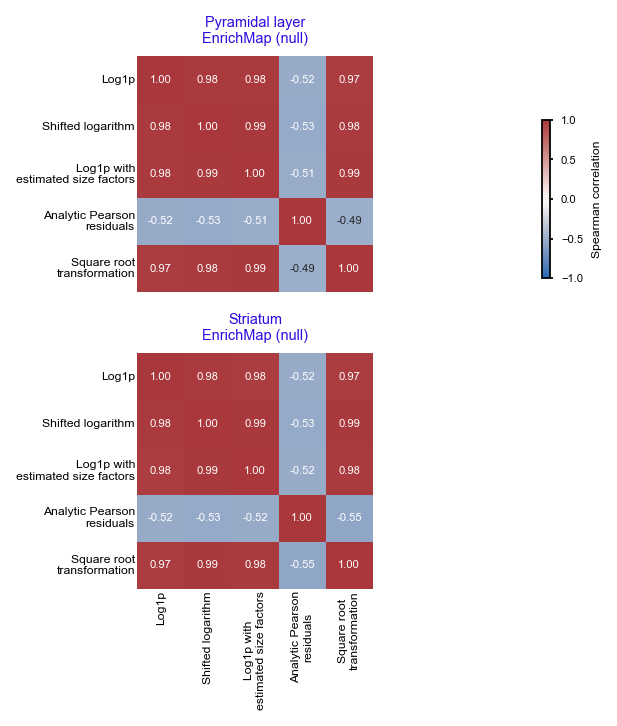

In [17]:
# 12. Sup. Fig. 8d: Spearman correlation between normalisations
# Every method in one fixed order

fig, axes = plt.subplots(
    len(regions),
    len(methods),
    figsize=(3.8 * len(methods), 2.25 * len(regions)),
    squeeze=False,
)

heat_labels = [short_labels[k] for k in normalisation_methods]

for i, ct in enumerate(regions):
    for j, m in enumerate(methods):
        ax = axes[i, j]

        sns.heatmap(
            spearman[(ct, m)].loc[normalisation_methods, normalisation_methods],
            cmap="vlag",
            vmin=-1,
            vmax=1,
            annot=True,
            fmt=".2f",
            annot_kws={"fontsize": 5},
            square=True,
            linewidths=0,
            ax=ax,
            cbar=False,
        )

        ax.set_title(f"{region_labels[ct]}\n{m}", fontsize=6.5, color=colours[m])
        ax.set_xlabel("")
        ax.set_ylabel("")

        ax.set_xticks(np.arange(len(heat_labels)) + 0.5)
        ax.set_yticks(np.arange(len(heat_labels)) + 0.5)

        ax.set_xticklabels(
            heat_labels if i == len(regions) - 1 else [], rotation=90, fontsize=5.5
        )
        ax.set_yticklabels(heat_labels if j == 0 else [], rotation=0, fontsize=5.5)
        ax.tick_params(length=0, pad=1)

plt.tight_layout(w_pad=0.3, h_pad=1.8, rect=[0, 0, 0.93, 1])

cax = fig.add_axes([0.945, 0.62, 0.012, 0.22])
cb = fig.colorbar(ScalarMappable(norm=Normalize(-1, 1), cmap="vlag"), cax=cax)
cb.set_label("Spearman correlation", fontsize=5.5)
cb.ax.tick_params(labelsize=5, length=1.5)

plt.savefig(figure_dir + "ExtendedDataFig6d_spearman.pdf", bbox_inches="tight")
plt.show()

spearman_long.to_csv(source_dir + "ExtendedDataFig6d_spearman.csv", index=False)

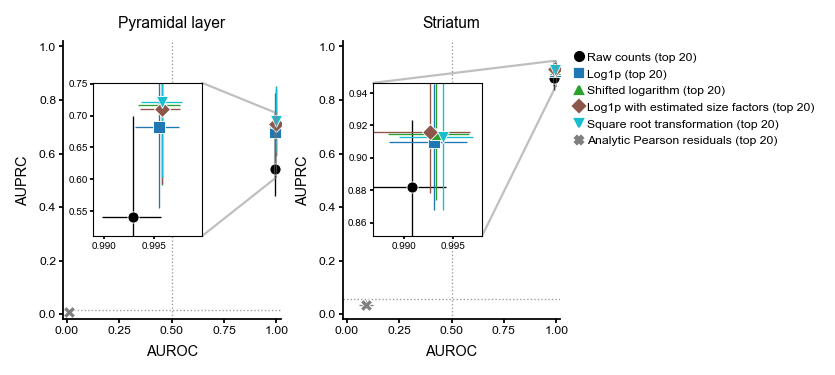

In [18]:
# 13. Sup. Fig. 8e: region recovery per normalisation (AUROC vs AUPRC, colour = method, marker = normalisation)
marker_colours = {**norm_colours, "raw": "#000000"}


def plot_auroc_auprc(ax, t):
    """
    One point per method and normalisation with 95% bootstrap whiskers.

    Parameters
    ----------
    ax : plt.Axes
        Target axes.
    t : pd.DataFrame
        Rows of `plotted_recovery` (method, layer, AUROC, AUPRC and their _lo/_hi columns).
    """
    for _, r in t.iterrows():
        ax.errorbar(
            r["AUROC"], r["AUPRC"],
            xerr=[[r["AUROC"] - r["AUROC_lo"]], [r["AUROC_hi"] - r["AUROC"]]],
            yerr=[[r["AUPRC"] - r["AUPRC_lo"]], [r["AUPRC_hi"] - r["AUPRC"]]],
            fmt=norm_markers[r["layer"]], color=marker_colours[r["layer"]], ms=5, mec="white", mew=0.4,
            elinewidth=0.6, capsize=0,
        )
    ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(5.2, 2.3))
for ax, ct in zip(axes, regions):
    t = plotted_recovery[plotted_recovery["region"] == region_labels[ct]]
    plot_auroc_auprc(ax, t)
    ax.axvline(0.5, ls=":", c="0.6", lw=0.6)
    ax.axhline(labels[ct].mean(), ls=":", c="0.6", lw=0.6)
    ax.set_xlabel("AUROC", fontsize=6.5)
    ax.set_ylabel("AUPRC", fontsize=6.5)
    ax.set_title(region_labels[ct], fontsize=7)
    ax.tick_params(labelsize=5.5, length=2, pad=1)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    sns.despine(ax=ax)
    # inset: the cluster of successful runs (AUROC > 0.85) enlarged
    hi = t[t["AUROC"] > 0.85]
    inset = ax.inset_axes([0.14, 0.30, 0.5, 0.55])
    plot_auroc_auprc(inset, hi)
    pad_x = max(0.004, 0.08 * (hi["AUROC"].max() - hi["AUROC"].min()))
    pad_y = max(0.03, 0.08 * (hi["AUPRC"].max() - hi["AUPRC"].min()))
    inset.set_xlim(hi["AUROC"].min() - pad_x, hi["AUROC"].max() + pad_x)
    inset.set_ylim(hi["AUPRC"].min() - pad_y, hi["AUPRC"].max() + pad_y)
    inset.tick_params(labelsize=4.5, length=1.5, pad=1)
    for side in inset.spines.values():
        side.set_linewidth(0.5)
    ax.indicate_inset_zoom(inset, edgecolor="0.5", lw=0.5)
handles = [Line2D([0], [0], marker=norm_markers[k], ls="", color=marker_colours[k], ms=4,
                  label=f"{method_labels[k]} (top {plotted_size[k]})") for k in map_order]
axes[1].legend(handles=handles, frameon=False, fontsize=5.5, loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.savefig(figure_dir + "ExtendedDataFig6e_region_recovery.pdf", bbox_inches="tight")
plt.show()
panel_e = plotted_recovery.dropna(axis=1, how="all").drop(columns=["plotted"])
panel_e.to_csv(source_dir + "ExtendedDataFig6e_region_recovery.csv", index=False)